<a href="https://colab.research.google.com/github/ReyAndrey22/Machine-Learning-Laboratories/blob/main/Laborator_3_%C3%8Env%C4%83%C8%9Bare_automat%C4%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Import the libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from pandas.core.common import random_state
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.utils import resample

In [ ]:
#Load the dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Laboratoare_Învățare_automată/Lab3/ecommerceDataset.csv')
df.head(10)

,Household,"Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. This is an special series of paintings which makes your wall very beautiful and gives a royal touch. This painting is ready to hang, you would be proud to possess this unique painting that is a niche apart. We use only the most modern and efficient printing technology on our prints, with only the and inks and precision epson, roland and hp printers. This innovative hd printing technique results in durable and spectacular looking prints of the highest that last a lifetime. We print solely with top-notch 100% inks, to achieve brilliant and true colours. Due to their high level of uv resistance, our prints retain their beautiful colours for many years. Add colour and style to your living space with this digitally printed painting. Some are for pleasure and some for eternal bliss.so bring home this elegant print that is lushed with rich colors that makes it nothing but sheer elegance to be to your friends and family.it would be treasured forever by whoever your lucky recipient is. Liven up your place with these intriguing paintings that are high definition hd graphic digital prints for home, office or any room."
0,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x ..."
1,Household,SAF 'UV Textured Modern Art Print Framed' Pain...
2,Household,"SAF Flower Print Framed Painting (Synthetic, 1..."
3,Household,Incredible Gifts India Wooden Happy Birthday U...
4,Household,Pitaara Box Romantic Venice Canvas Painting 6m...
5,Household,Paper Plane Design Starry Night Vangoh Wall Ar...
6,Household,Pitaara Box Romantic Venice Canvas Painting 6m...
7,Household,SAF 'Ganesh Modern Art Print' Painting (Synthe...
8,Household,Paintings Villa UV Textured Modern Art Print F...
9,Household,Painting Mantra Art Street - Jardin Bird Frame...


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Laboratoare_Învățare_automată/Lab3/ecommerceDataset.csv', header=None, names=['Category', 'Description'])
df.head(10)

,Category,Description
0,Household,Paper Plane Design Framed Wall Hanging Motivat...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x ..."
2,Household,SAF 'UV Textured Modern Art Print Framed' Pain...
3,Household,"SAF Flower Print Framed Painting (Synthetic, 1..."
4,Household,Incredible Gifts India Wooden Happy Birthday U...
5,Household,Pitaara Box Romantic Venice Canvas Painting 6m...
6,Household,Paper Plane Design Starry Night Vangoh Wall Ar...
7,Household,Pitaara Box Romantic Venice Canvas Painting 6m...
8,Household,SAF 'Ganesh Modern Art Print' Painting (Synthe...
9,Household,Paintings Villa UV Textured Modern Art Print F...


In [ ]:
#Info about dataset
print("Shape of the dataset: " + str(df.shape))
print("Category: " + str(df['Category'].unique()))
df.info()
print(df.duplicated().sum())
print(df.isnull().sum())

Shape of the dataset: (50425, 2)
Category: ['Household' 'Books' 'Clothing & Accessories' 'Electronics']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50425 entries, 0 to 50424
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Category     50425 non-null  object
 1   Description  50424 non-null  object
dtypes: object(2)
memory usage: 788.0+ KB
22622
Category       0
Description    1
dtype: int64


In [ ]:
df = df.drop_duplicates()
df = df.dropna()
print("Shape of the dataset: " + str(df.shape))
print(df['Category'].value_counts())

Shape of the dataset: (27802, 2)
Category
Household                 10564
Books                      6256
Clothing & Accessories     5674
Electronics                5308
Name: count, dtype: int64


In [ ]:
#Oversampling
df_household = df[df['Category'] == 'Household']
df_books = df[df['Category'] == 'Books']
df_clothing = df[df['Category'] == 'Clothing & Accessories']
df_electronics = df[df['Category'] == 'Electronics']

df_books_up = resample(df_books,
                       replace=True,
                       n_samples=len(df_household),
                       random_state=42)
df_clothing_up = resample(df_clothing,
                          replace=True,
                          n_samples=len(df_household),
                          random_state=42)
df_electronics_up = resample(df_electronics,
                             replace=True,
                             n_samples=len(df_household),
                             random_state=42)

df_balanced = pd.concat([df_household, df_books_up, df_clothing_up, df_electronics_up])

print(df_balanced.Category.value_counts())

Category
Household                 10564
Books                     10564
Clothing & Accessories    10564
Electronics               10564
Name: count, dtype: int64


In [ ]:
#Splitting the features
X = df_balanced['Description']
y = df_balanced['Category']

In [ ]:
#Splitting the dataset into train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [ ]:
TF_IDF = TfidfVectorizer()
X_train_TF_IDF = TF_IDF.fit_transform(X_train)
X_test_TF_IDF = TF_IDF.transform(X_test)

In [ ]:
#Naive Bayes
model_nb = MultinomialNB()
model_nb.fit(X_train_TF_IDF, y_train)
y_pred_nb = model_nb.predict(X_test_TF_IDF)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))


Accuracy: 0.9458116422148604
                        precision    recall  f1-score   support

                 Books       0.97      0.91      0.94      2056
Clothing & Accessories       0.96      0.98      0.97      2115
           Electronics       0.94      0.94      0.94      2125
             Household       0.91      0.94      0.93      2156

              accuracy                           0.95      8452
             macro avg       0.95      0.95      0.95      8452
          weighted avg       0.95      0.95      0.95      8452



In [ ]:
#Decision Tree
model_dt = DecisionTreeClassifier(random_state=1, max_depth=50)
model_dt.fit(X_train_TF_IDF, y_train)
y_pred_dt = model_dt.predict(X_test_TF_IDF)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.9184808329389493
                        precision    recall  f1-score   support

                 Books       0.92      0.94      0.93      2056
Clothing & Accessories       0.97      0.96      0.97      2115
           Electronics       0.93      0.91      0.92      2125
             Household       0.86      0.86      0.86      2156

              accuracy                           0.92      8452
             macro avg       0.92      0.92      0.92      8452
          weighted avg       0.92      0.92      0.92      8452



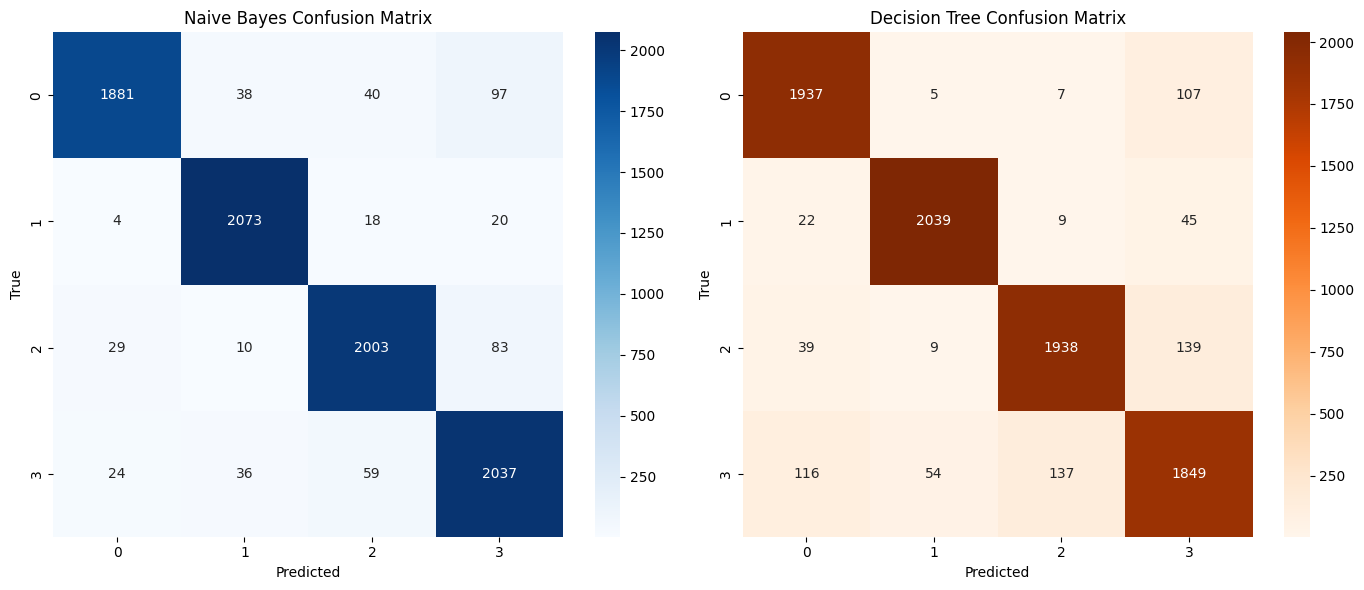

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d', ax=axes[0], cmap='Blues')
axes[0].set_title('Naive Bayes Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', ax=axes[1], cmap='Oranges')
axes[1].set_title('Decision Tree Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.show()